# 🌍 Dünya İçin Tehlikeli Asteroit Tespiti
### NASA Near-Earth Object (NEO) Veri Seti — PHA (Potentially Hazardous Asteroid) Sınıflandırması

---

**Amaç:** NASA'nın NEO verisini kullanarak Dünya için potansiyel olarak tehlikeli asteroitleri (PHA) makine öğrenmesi modelleriyle tespit etmek.

**Yöntem:**
- Veri ön işleme & özellik mühendisliği
- SMOTE ile sınıf dengesizliğini giderme
- Random Forest + XGBoost eğitimi
- Stratified K-Fold Cross Validation
- Kapsamlı görselleştirmeler

In [1]:
# ============================================================
# 1. KÜTÜPHANELER
# ============================================================
import pandas as pd
import numpy as np
import glob
import warnings
warnings.filterwarnings('ignore')

# Modeller
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Metrikler
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix,
    roc_curve, precision_recall_curve, average_precision_score
)

# Görselleştirme
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

SPACE_BG   = '#0d1117'
SAFE_COLOR = '#2196F3'
PHA_COLOR  = '#FF4444'
GOLD       = '#FFC107'
GREEN      = '#4CAF50'

print('✅ Kütüphaneler başarıyla yüklendi.')

✅ Kütüphaneler başarıyla yüklendi.


In [2]:
# ============================================================
# 2. VERİ YÜKLEME
# ============================================================
file_path = glob.glob('/kaggle/input/**/*near_earth*.csv', recursive=True)[0]
df = pd.read_csv(file_path, low_memory=False)

print(f'📦 Veri seti boyutu : {df.shape[0]:,} satır × {df.shape[1]} sütun')
print(f'🎯 Hedef dağılımı   :')
vc = df['pha'].value_counts()
print(f'   Tehlikeli (PHA=1) : {vc.get("Y", vc.get(1, 0)):,}')
print(f'   Güvenli   (PHA=0) : {vc.get("N", vc.get(0, 0)):,}')
df.head(3)

📦 Veri seti boyutu : 41,281 satır × 29 sütun
🎯 Hedef dağılımı   :
   Tehlikeli (PHA=1) : 2,539
   Güvenli   (PHA=0) : 38,742


,spkid,full_name,pdes,name,pha,H,diameter_km,diameter_m,diameter_is_estimated,size_category,...,per_y,moid_au,moid_km,moid_lunar_distances,n,condition_code,first_obs,last_obs,data_arc,data_arc_years
0,20000433,433 Eros (A898 PA),433,Eros,False,10.39,16.84000,16840.0,False,Large (>1 km) — City killer+,...,1.76,0.1480,22140485.0,57.60,0.5598,0.0,1893-10-29,2021-05-13,46582.0,127.53
1,20000719,719 Albert (A911 TB),719,Albert,False,15.59,2.70683,2706.8,True,Large (>1 km) — City killer+,...,4.28,0.2010,30069172.0,78.22,0.2302,0.0,1911-10-04,2026-03-20,41806.0,114.46
2,20000887,887 Alinda (A918 AA),887,Alinda,False,13.82,4.20000,4200.0,False,Large (>1 km) — City killer+,...,3.89,0.0797,11922950.0,31.02,0.2533,0.0,1918-02-09,2025-08-27,39281.0,107.55


In [3]:
# ============================================================
# 3. VERİ ÖN İŞLEME
# ============================================================

# Hedef değişken
if df['pha'].dtype == object:
    df['pha'] = df['pha'].map({'Y': 1, 'N': 0})
df['pha'] = df['pha'].astype(int)

# Veri sızıntısı ve anlamsız sütunları kaldır
cols_to_drop = [
    'spkid', 'full_name', 'pdes', 'name', 'size_category', 'class',
    'albedo', 'rot_per',
    'diameter_m', 'diameter_is_estimated', 'diameter_km',
    'moid_km', 'moid_lunar_distances',
    'first_obs', 'last_obs',
    'condition_code', 'data_arc', 'data_arc_years',
    'H', 'moid_au'   # doğrudan PHA tanımında kullanılan leaky sütunlar
]
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
df_clean = df_clean.dropna()

print(f'🧹 Temizlendikten sonra: {df_clean.shape[0]:,} satır × {df_clean.shape[1]} sütun')

🧹 Temizlendikten sonra: 41,281 satır × 9 sütun


In [4]:
# ============================================================
# 4. ÖZELLİK MÜHENDİSLİĞİ
# ============================================================

# Yörünge parametrelerinden türetilen anlamlı özellikler
df_clean['aphelion_dist']   = df_clean['a'] * (1 + df_clean['e'])   # Günesten en uzak nokta (AU)
df_clean['perihelion_dist'] = df_clean['a'] * (1 - df_clean['e'])   # Günesten en yakın nokta (AU)
df_clean['orbit_energy']    = -1 / (2 * df_clean['a'])              # Özgül yörünge enerjisi
df_clean['velocity_proxy']  = np.sqrt(1 / df_clean['a'])            # Hız proxy (Kepler 3. Yasa)

# Özellik ve hedef ayrımı
X = df_clean.drop(columns=['pha'])
y = df_clean['pha']

feature_names = X.columns.tolist()
print(f'🔧 Toplam özellik sayısı: {len(feature_names)}')
print(f'   Özellikler: {feature_names}')

🔧 Toplam özellik sayısı: 12
   Özellikler: ['e', 'a', 'i', 'q', 'ad', 'per', 'per_y', 'n', 'aphelion_dist', 'perihelion_dist', 'orbit_energy', 'velocity_proxy']


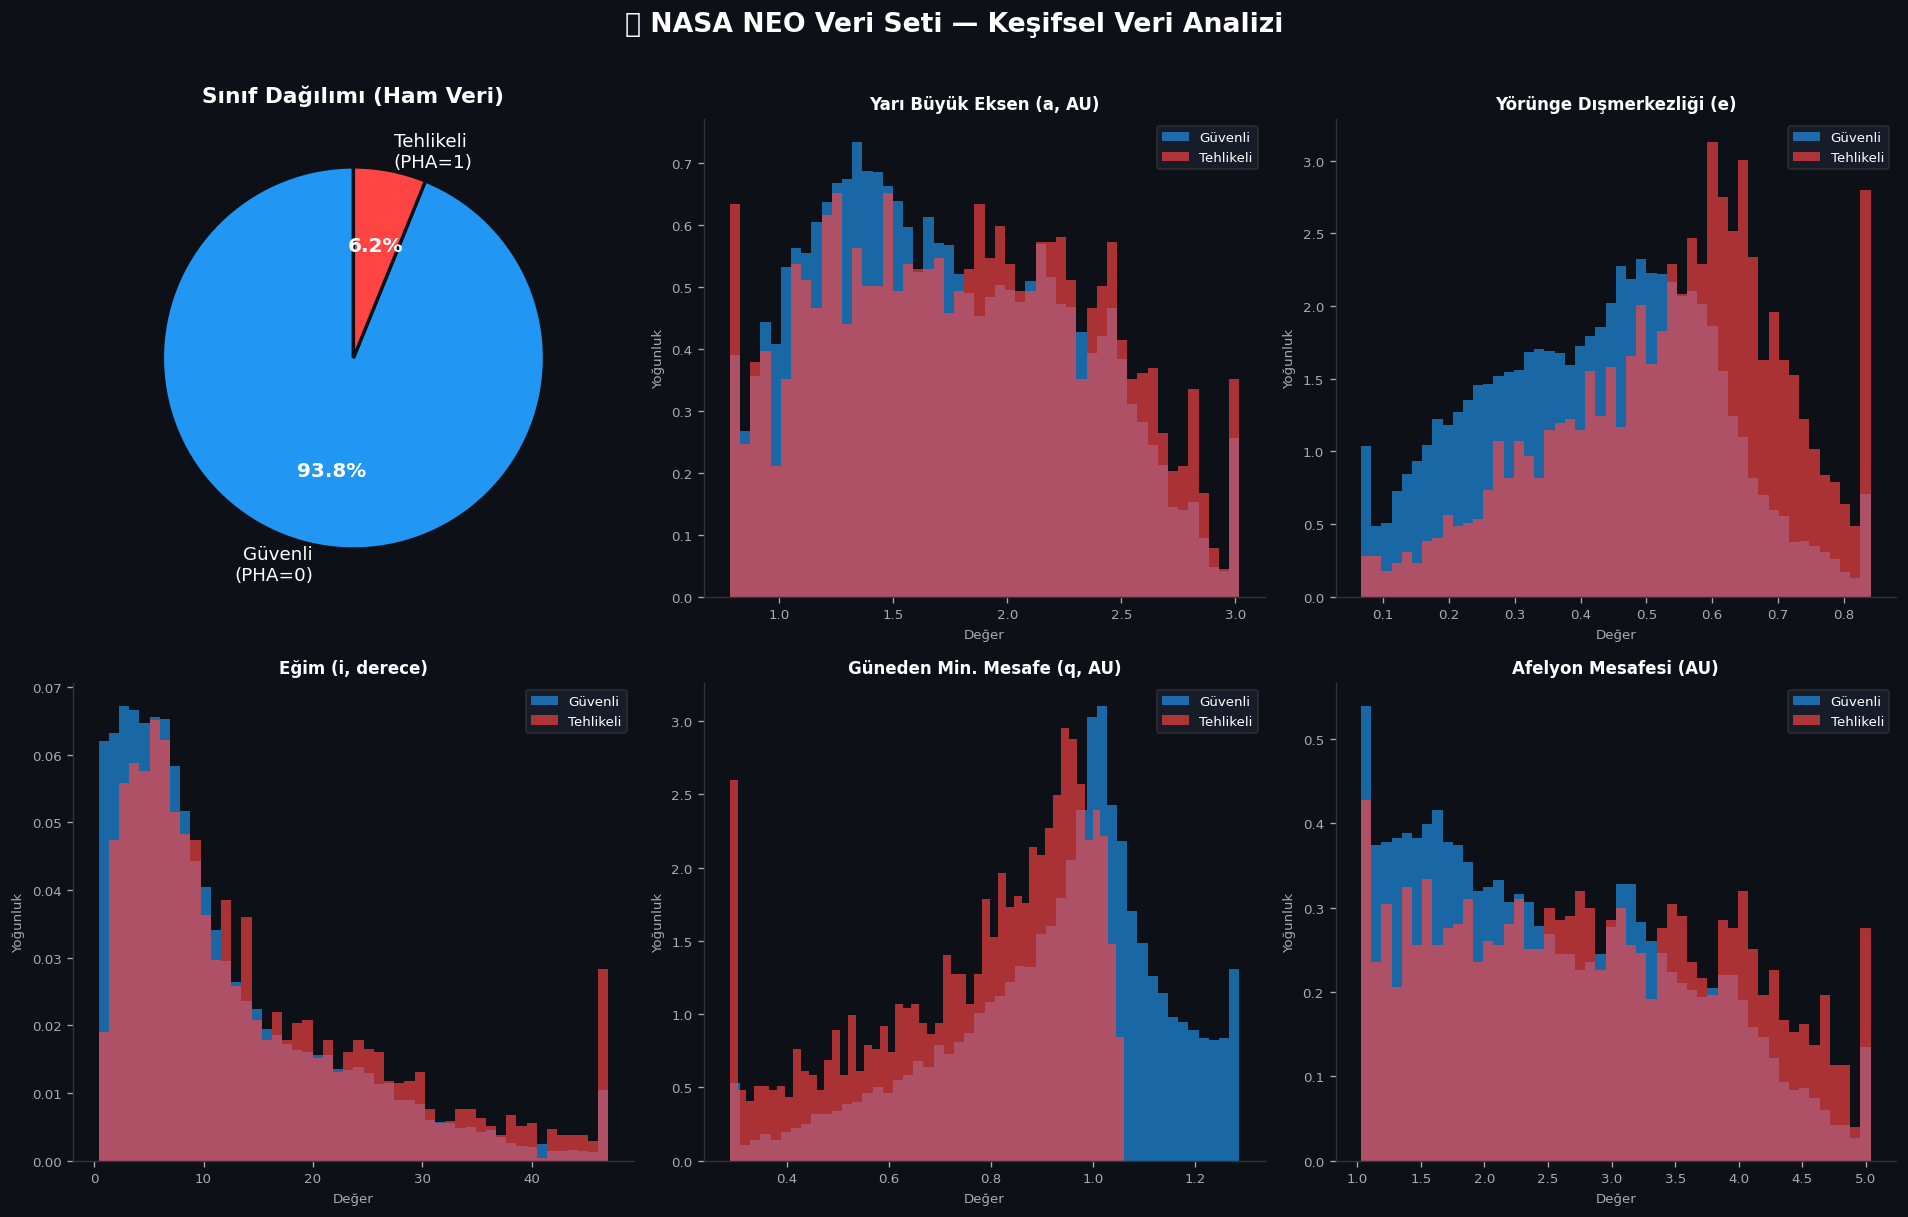

📊 EDA grafiği kaydedildi: 01_eda.png


In [5]:
# ============================================================
# 5. GÖRSELLEŞTİRME I — Sınıf Dağılımı & Özellik Dağılımları
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.patch.set_facecolor(SPACE_BG)

# --- Sınıf dengesi (pasta) ---
ax = axes[0, 0]
ax.set_facecolor(SPACE_BG)
counts = y.value_counts()
wedges, texts, autotexts = ax.pie(
    counts, labels=['Güvenli\n(PHA=0)', 'Tehlikeli\n(PHA=1)'],
    colors=[SAFE_COLOR, PHA_COLOR],
    autopct='%1.1f%%', startangle=90,
    textprops={'color': 'white', 'fontsize': 11},
    wedgeprops={'edgecolor': SPACE_BG, 'linewidth': 2}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
ax.set_title('Sınıf Dağılımı (Ham Veri)', color='white', fontsize=13, fontweight='bold', pad=10)

# --- Özellik dağılımları ---
# Sadece 5 özellik: pasta grafiği axes[0,0]'da, geri kalan 5 hücreye dağıtılıyor
plot_features = ['a', 'e', 'i', 'q', 'aphelion_dist']
plot_titles   = ['Yarı Büyük Eksen (a, AU)', 'Yörünge Dışmerkezliği (e)',
                 'Eğim (i, derece)', 'Güneden Min. Mesafe (q, AU)',
                 'Afelyon Mesafesi (AU)']

# axes pozisyonları: pasta [0,0] zaten kullanıldı, geri kalan 5 hücre
ax_positions = [(0,1), (0,2), (1,0), (1,1), (1,2)]

for (r, c), feat, title in zip(ax_positions, plot_features, plot_titles):
    ax = axes[r, c]
    ax.set_facecolor(SPACE_BG)
    
    if feat not in X.columns:
        ax.set_visible(False)
        continue
    
    for cls, color, label in [(0, SAFE_COLOR, 'Güvenli'), (1, PHA_COLOR, 'Tehlikeli')]:
        data = X.loc[y == cls, feat].clip(
            X[feat].quantile(0.01), X[feat].quantile(0.99)
        )
        ax.hist(data, bins=50, alpha=0.65, color=color, label=label, density=True)
    
    ax.set_title(title, color='white', fontsize=10, fontweight='bold')
    ax.tick_params(colors='#aaaaaa', labelsize=8)
    ax.set_xlabel('Değer', color='#aaaaaa', fontsize=8)
    ax.set_ylabel('Yoğunluk', color='#aaaaaa', fontsize=8)
    for spine in ax.spines.values():
        spine.set_edgecolor('#333333')
    ax.legend(fontsize=8, labelcolor='white',
              facecolor='#1a1f2e', edgecolor='#333333')

fig.suptitle('🌌 NASA NEO Veri Seti — Keşifsel Veri Analizi',
             color='white', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('01_eda.png', dpi=130, bbox_inches='tight', facecolor=SPACE_BG)
plt.show()
print('📊 EDA grafiği kaydedildi: 01_eda.png')

In [6]:
# ============================================================
# 6. SMOTE + TRAIN/TEST BÖLME
# ============================================================

X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Ölçekleme
scaler = StandardScaler()
X_train_raw_sc = scaler.fit_transform(X_train_raw)
X_test_sc      = scaler.transform(X_test)

# SMOTE — sadece eğitim setine uygula!
smote = SMOTE(random_state=42, k_neighbors=5)
X_train, y_train = smote.fit_resample(X_train_raw_sc, y_train_raw)

before = y_train_raw.value_counts()
after  = pd.Series(y_train).value_counts()

print('⚖️  SMOTE Dengesi:')
print(f'   Önce  — Güvenli: {before[0]:,}  |  Tehlikeli: {before[1]:,}')
print(f'   Sonra — Güvenli: {after[0]:,}  |  Tehlikeli: {after[1]:,}')
print(f'\n🧪 Test seti (dengeli değil, gerçekçi): {y_test.value_counts().to_dict()}')

⚖️  SMOTE Dengesi:
   Önce  — Güvenli: 30,993  |  Tehlikeli: 2,031
   Sonra — Güvenli: 30,993  |  Tehlikeli: 30,993

🧪 Test seti (dengeli değil, gerçekçi): {0: 7749, 1: 508}


In [7]:
# ============================================================
# 7. MODEL EĞİTİMİ — RANDOM FOREST
# ============================================================

print('🌲 Random Forest eğitiliyor...')
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_pred      = rf_model.predict(X_test_sc)
rf_prob      = rf_model.predict_proba(X_test_sc)[:, 1]

rf_acc  = accuracy_score(y_test, rf_pred)
rf_f1   = f1_score(y_test, rf_pred)
rf_auc  = roc_auc_score(y_test, rf_prob)
rf_ap   = average_precision_score(y_test, rf_prob)

print('\n--- RANDOM FOREST Sonuçları ---')
print(f'  Accuracy          : %{rf_acc * 100:.2f}')
print(f'  F1 Score (PHA=1)  : %{rf_f1 * 100:.2f}')
print(f'  ROC-AUC           : {rf_auc:.4f}')
print(f'  Avg Precision     : {rf_ap:.4f}')
print(classification_report(y_test, rf_pred,
                             target_names=['Güvenli', 'Tehlikeli'],
                             zero_division=0))

🌲 Random Forest eğitiliyor...

--- RANDOM FOREST Sonuçları ---
  Accuracy          : %78.16
  F1 Score (PHA=1)  : %20.75
  ROC-AUC           : 0.7484
  Avg Precision     : 0.1282
              precision    recall  f1-score   support

     Güvenli       0.96      0.80      0.87      7749
   Tehlikeli       0.13      0.46      0.21       508

    accuracy                           0.78      8257
   macro avg       0.55      0.63      0.54      8257
weighted avg       0.91      0.78      0.83      8257



In [8]:
# ============================================================
# 8. MODEL EĞİTİMİ — XGBOOST
# ============================================================

print('🚀 XGBoost eğitiliyor...')
xgb_model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test_sc)
xgb_prob = xgb_model.predict_proba(X_test_sc)[:, 1]

xgb_acc  = accuracy_score(y_test, xgb_pred)
xgb_f1   = f1_score(y_test, xgb_pred)
xgb_auc  = roc_auc_score(y_test, xgb_prob)
xgb_ap   = average_precision_score(y_test, xgb_prob)

print('\n--- XGBOOST Sonuçları ---')
print(f'  Accuracy          : %{xgb_acc * 100:.2f}')
print(f'  F1 Score (PHA=1)  : %{xgb_f1 * 100:.2f}')
print(f'  ROC-AUC           : {xgb_auc:.4f}')
print(f'  Avg Precision     : {xgb_ap:.4f}')
print(classification_report(y_test, xgb_pred,
                             target_names=['Güvenli', 'Tehlikeli'],
                             zero_division=0))

🚀 XGBoost eğitiliyor...

--- XGBOOST Sonuçları ---
  Accuracy          : %69.26
  F1 Score (PHA=1)  : %21.33
  ROC-AUC           : 0.7649
  Avg Precision     : 0.1461
              precision    recall  f1-score   support

     Güvenli       0.97      0.69      0.81      7749
   Tehlikeli       0.13      0.68      0.21       508

    accuracy                           0.69      8257
   macro avg       0.55      0.69      0.51      8257
weighted avg       0.92      0.69      0.77      8257



In [9]:
# ============================================================
# 9. CROSS-VALIDATION (Overfitting kontrolü)
# ============================================================

print('🔄 Stratified 5-Fold Cross Validation...')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# CV için SMOTE'suz, ölçeklenmiş eğitim verisi üzerinde
rf_cv  = cross_val_score(rf_model,  X_train_raw_sc, y_train_raw, cv=cv, scoring='f1', n_jobs=-1)
xgb_cv = cross_val_score(xgb_model, X_train_raw_sc, y_train_raw, cv=cv, scoring='f1', n_jobs=-1)

print('\n📊 Cross-Validation F1 Skorları:')
print(f'   RF  — Katlara göre: {[f"%{s*100:.1f}" for s in rf_cv]}')
print(f'   RF  — Ortalama: %{rf_cv.mean()*100:.2f} (±{rf_cv.std()*100:.2f})')
print(f'   XGB — Katlara göre: {[f"%{s*100:.1f}" for s in xgb_cv]}')
print(f'   XGB — Ortalama: %{xgb_cv.mean()*100:.2f} (±{xgb_cv.std()*100:.2f})')

# Overfitting testi
rf_train_f1  = f1_score(y_train, rf_model.predict(X_train))
xgb_train_f1 = f1_score(y_train, xgb_model.predict(X_train))

print('\n🔍 Overfitting Analizi (Train vs Test F1):')
print(f'   RF  — Train: %{rf_train_f1*100:.2f}  |  Test: %{rf_f1*100:.2f}  |  Fark: {abs(rf_train_f1 - rf_f1)*100:.2f} puan')
print(f'   XGB — Train: %{xgb_train_f1*100:.2f}  |  Test: %{xgb_f1*100:.2f}  |  Fark: {abs(xgb_train_f1 - xgb_f1)*100:.2f} puan')

🔄 Stratified 5-Fold Cross Validation...

📊 Cross-Validation F1 Skorları:
   RF  — Katlara göre: ['%1.9', '%1.4', '%0.9', '%2.8', '%2.3']
   RF  — Ortalama: %1.88 (±0.66)
   XGB — Katlara göre: ['%1.9', '%1.9', '%2.4', '%3.2', '%1.9']
   XGB — Ortalama: %2.27 (±0.53)

🔍 Overfitting Analizi (Train vs Test F1):
   RF  — Train: %96.26  |  Test: %20.75  |  Fark: 75.52 puan
   XGB — Train: %83.55  |  Test: %21.33  |  Fark: 62.23 puan


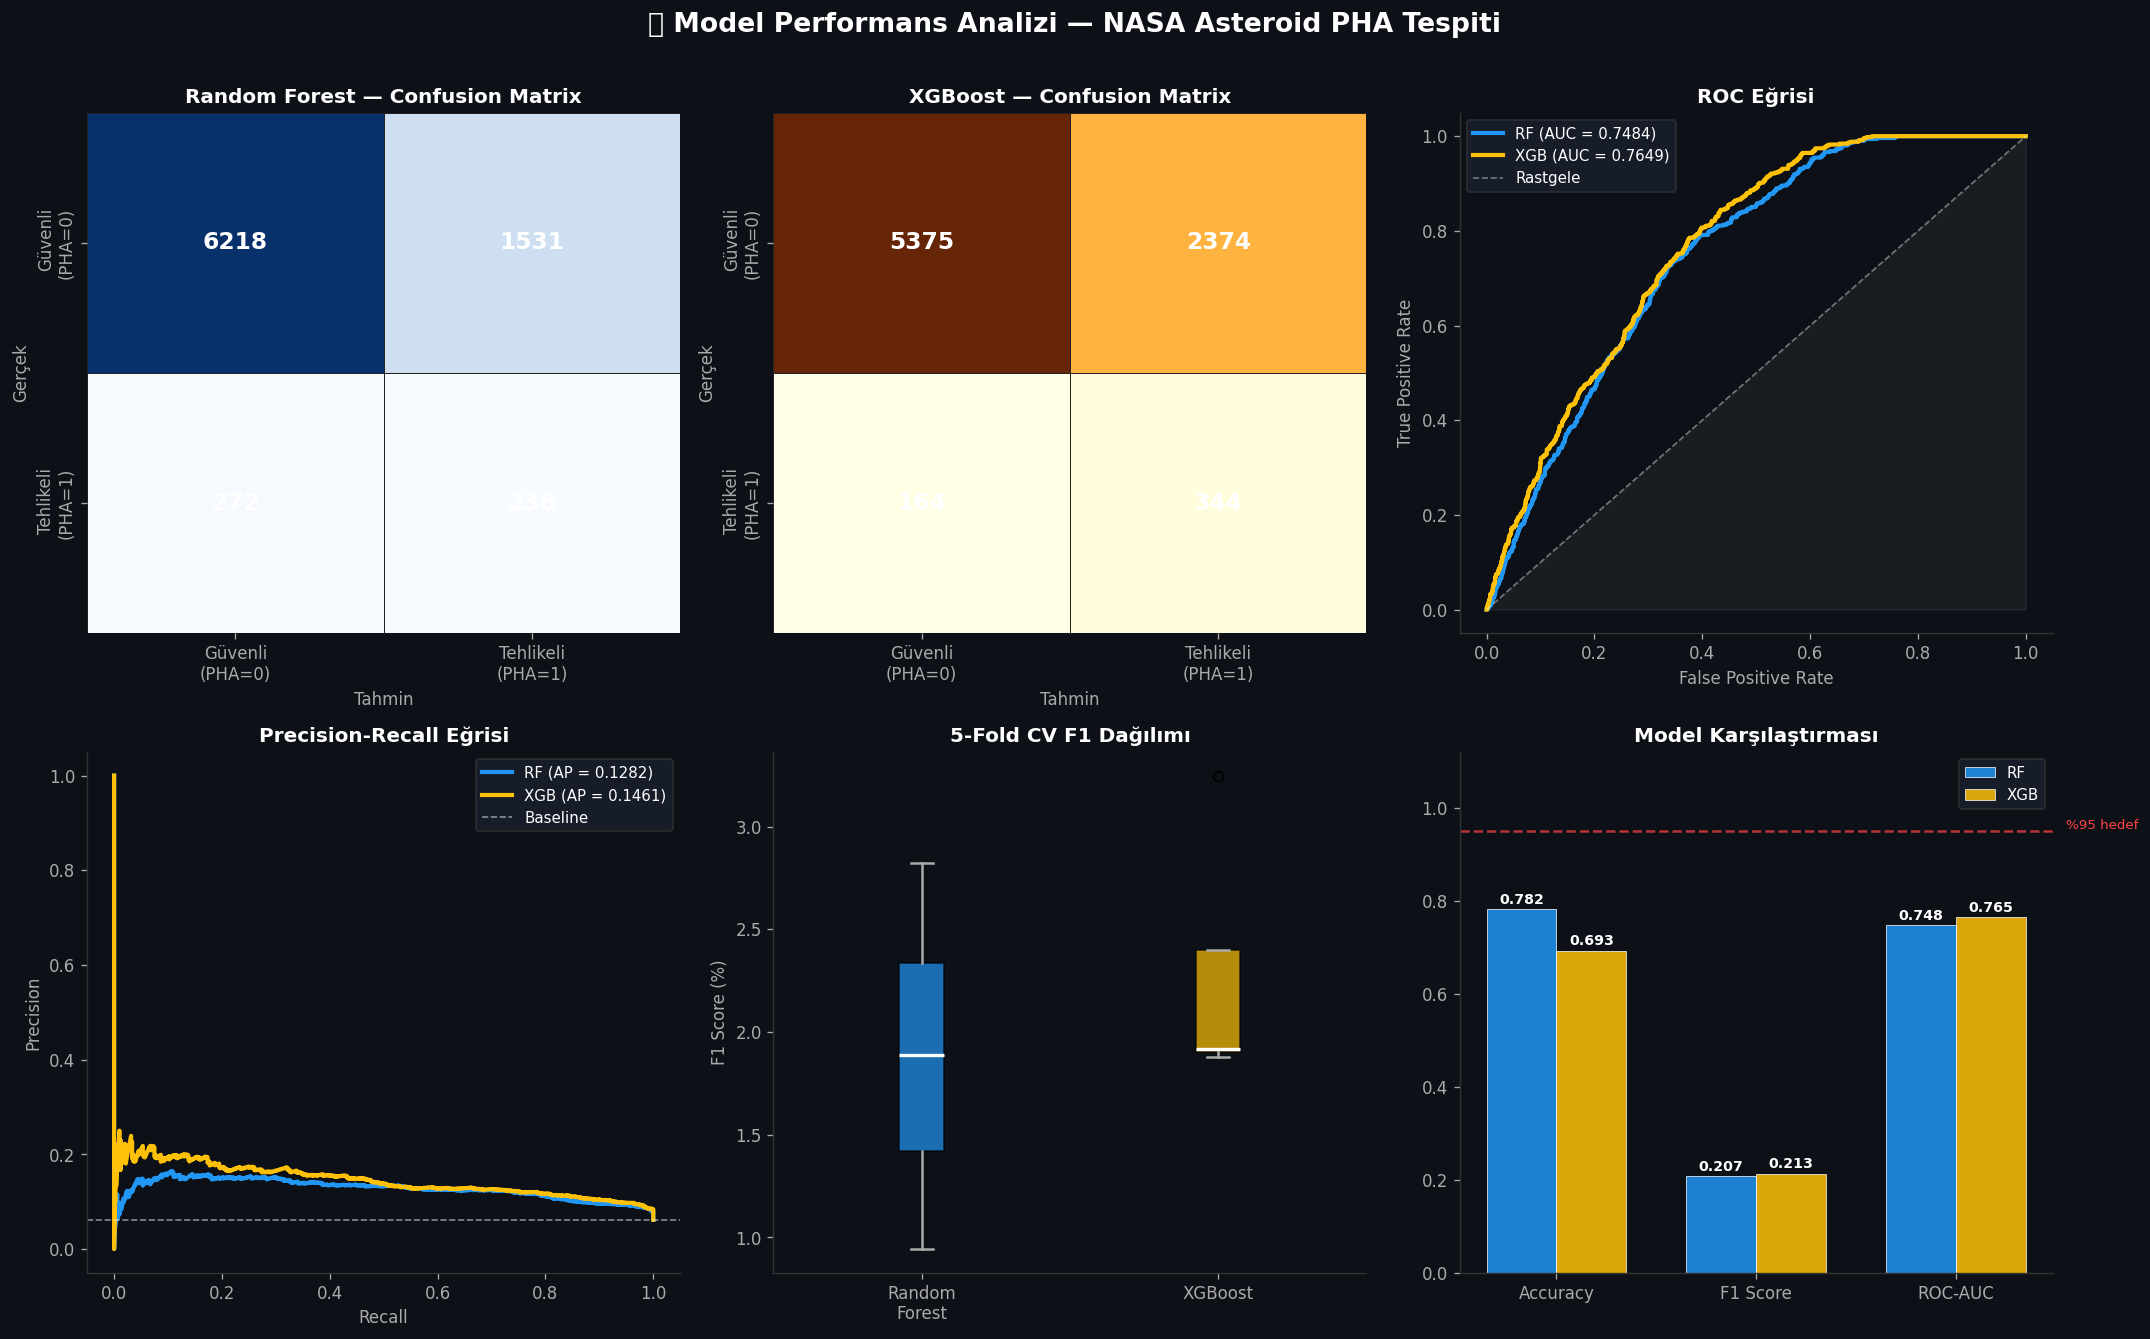

📊 Model performans grafiği kaydedildi: 02_model_performance.png


In [10]:
# ============================================================
# 10. GÖRSELLEŞTİRME II — Confusion Matrices + ROC + PR
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.patch.set_facecolor(SPACE_BG)

label_map = ['Güvenli\n(PHA=0)', 'Tehlikeli\n(PHA=1)']

for col, (name, pred, prob, color) in enumerate([
    ('Random Forest', rf_pred,  rf_prob,  SAFE_COLOR),
    ('XGBoost',       xgb_pred, xgb_prob, GOLD)
]):
    # --- Confusion Matrix ---
    ax = axes[0, col]
    ax.set_facecolor(SPACE_BG)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt='d', ax=ax,
        cmap='Blues' if col == 0 else 'YlOrBr',
        linewidths=0.5, linecolor='#222222',
        xticklabels=label_map, yticklabels=label_map,
        cbar=False, annot_kws={'fontsize': 14, 'fontweight': 'bold', 'color': 'white'}
    )
    ax.set_title(f'{name} — Confusion Matrix', color='white', fontsize=12, fontweight='bold')
    ax.set_xlabel('Tahmin', color='#aaaaaa', fontsize=10)
    ax.set_ylabel('Gerçek', color='#aaaaaa', fontsize=10)
    ax.tick_params(colors='#aaaaaa')

# --- ROC Curve ---
ax = axes[0, 2]
ax.set_facecolor(SPACE_BG)
for name, prob, color, auc_val in [
    ('RF',  rf_prob,  SAFE_COLOR, rf_auc),
    ('XGB', xgb_prob, GOLD,      xgb_auc)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, color=color, lw=2.5,
            label=f'{name} (AUC = {auc_val:.4f})')
ax.plot([0, 1], [0, 1], 'w--', lw=1, alpha=0.4, label='Rastgele')
ax.fill_between([0, 1], [0, 1], alpha=0.05, color='white')
ax.set_xlabel('False Positive Rate', color='#aaaaaa', fontsize=10)
ax.set_ylabel('True Positive Rate', color='#aaaaaa', fontsize=10)
ax.set_title('ROC Eğrisi', color='white', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, labelcolor='white', facecolor='#1a1f2e', edgecolor='#333333')
ax.tick_params(colors='#aaaaaa')
for sp in ax.spines.values(): sp.set_edgecolor('#333333')

# --- Precision-Recall Curves ---
ax = axes[1, 0]
ax.set_facecolor(SPACE_BG)
for name, prob, color, ap_val in [
    ('RF',  rf_prob,  SAFE_COLOR, rf_ap),
    ('XGB', xgb_prob, GOLD,      xgb_ap)
]:
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax.plot(rec, prec, color=color, lw=2.5,
            label=f'{name} (AP = {ap_val:.4f})')
ax.axhline(y_test.mean(), color='white', lw=1, ls='--', alpha=0.5, label='Baseline')
ax.set_xlabel('Recall', color='#aaaaaa', fontsize=10)
ax.set_ylabel('Precision', color='#aaaaaa', fontsize=10)
ax.set_title('Precision-Recall Eğrisi', color='white', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, labelcolor='white', facecolor='#1a1f2e', edgecolor='#333333')
ax.tick_params(colors='#aaaaaa')
for sp in ax.spines.values(): sp.set_edgecolor('#333333')

# --- Cross-Validation Kutu Grafiği ---
ax = axes[1, 1]
ax.set_facecolor(SPACE_BG)
bp = ax.boxplot(
    [rf_cv * 100, xgb_cv * 100],
    labels=['Random\nForest', 'XGBoost'],
    patch_artist=True,
    medianprops=dict(color='white', linewidth=2),
    flierprops=dict(marker='o', color='white', markersize=6)
)
colors_box = [SAFE_COLOR, GOLD]
for patch, c in zip(bp['boxes'], colors_box):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
for whisker in bp['whiskers']:
    whisker.set(color='#aaaaaa', linewidth=1.5)
for cap in bp['caps']:
    cap.set(color='#aaaaaa', linewidth=1.5)
ax.set_title('5-Fold CV F1 Dağılımı', color='white', fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Score (%)', color='#aaaaaa', fontsize=10)
ax.tick_params(colors='#aaaaaa')
for sp in ax.spines.values(): sp.set_edgecolor('#333333')

# --- Model Karşılaştırma (Bar) ---
ax = axes[1, 2]
ax.set_facecolor(SPACE_BG)
metrics = ['Accuracy', 'F1 Score', 'ROC-AUC']
rf_vals  = [rf_acc, rf_f1, rf_auc]
xgb_vals = [xgb_acc, xgb_f1, xgb_auc]
x = np.arange(len(metrics))
w = 0.35
b1 = ax.bar(x - w/2, rf_vals,  w, label='RF',  color=SAFE_COLOR, alpha=0.85, edgecolor='white', linewidth=0.5)
b2 = ax.bar(x + w/2, xgb_vals, w, label='XGB', color=GOLD,       alpha=0.85, edgecolor='white', linewidth=0.5)
for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.005,
                f'{h:.3f}', ha='center', va='bottom',
                color='white', fontsize=8.5, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, color='#aaaaaa', fontsize=10)
ax.set_ylim(0, 1.12)
ax.set_title('Model Karşılaştırması', color='white', fontsize=12, fontweight='bold')
ax.tick_params(colors='#aaaaaa')
ax.legend(fontsize=9, labelcolor='white', facecolor='#1a1f2e', edgecolor='#333333')
for sp in ax.spines.values(): sp.set_edgecolor('#333333')
ax.axhline(0.95, color=PHA_COLOR, lw=1.5, ls='--', alpha=0.7)
ax.text(2.55, 0.955, '%95 hedef', color=PHA_COLOR, fontsize=8)

fig.suptitle('🚀 Model Performans Analizi — NASA Asteroid PHA Tespiti',
             color='white', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('02_model_performance.png', dpi=130, bbox_inches='tight', facecolor=SPACE_BG)
plt.show()
print('📊 Model performans grafiği kaydedildi: 02_model_performance.png')

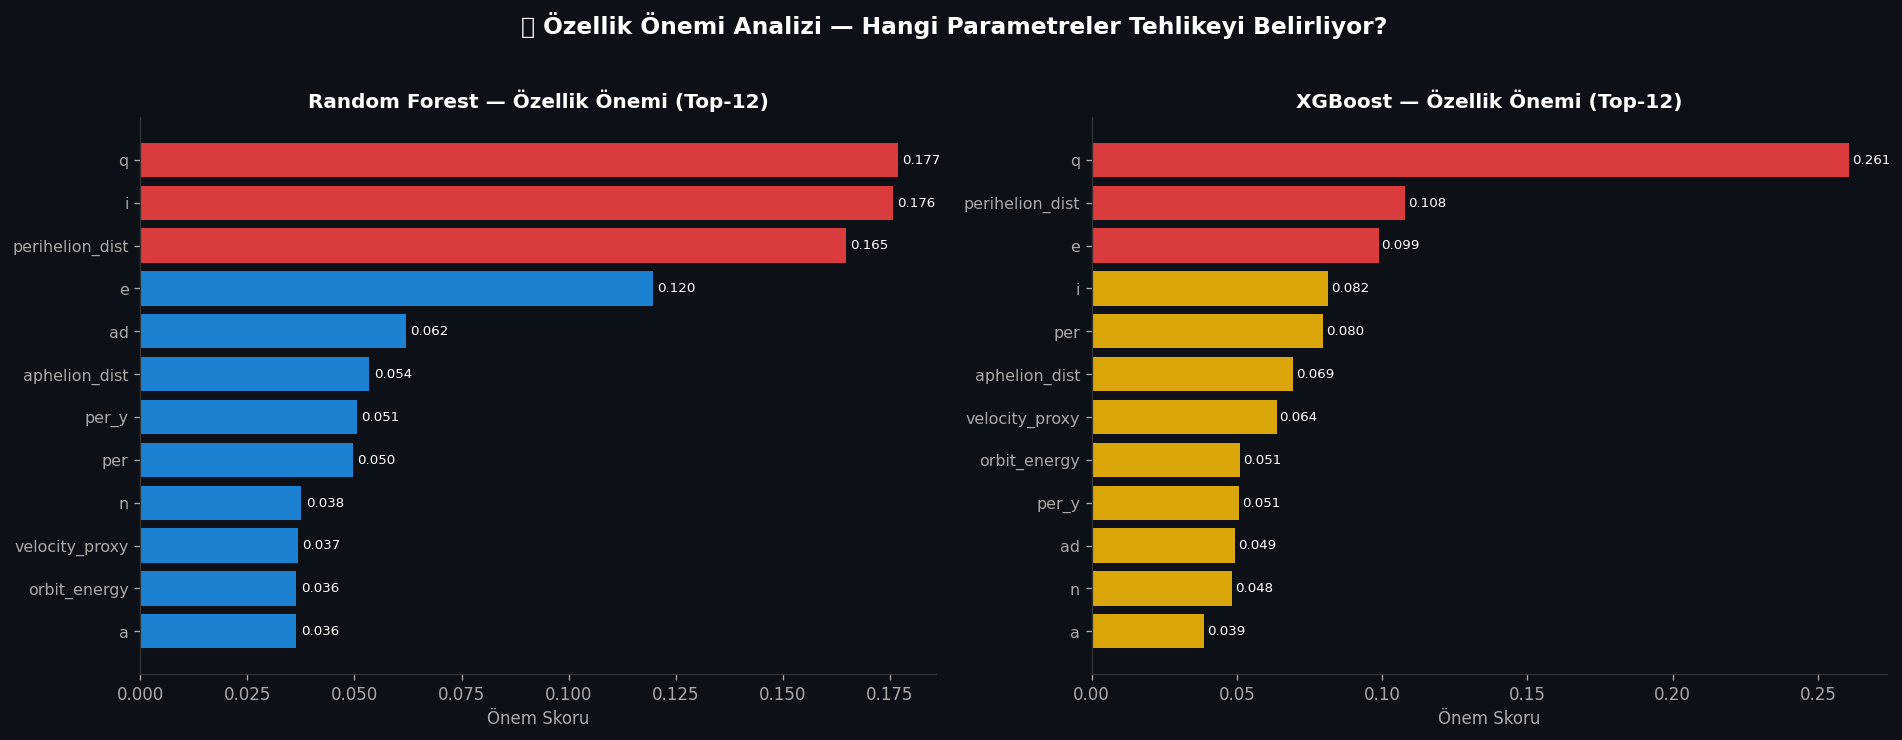

📊 Özellik önemi grafiği kaydedildi: 03_feature_importance.png


In [11]:
# ============================================================
# 11. GÖRSELLEŞTİRME III — Özellik Önemi
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor(SPACE_BG)

for ax, model, name, color in [
    (axes[0], rf_model,  'Random Forest', SAFE_COLOR),
    (axes[1], xgb_model, 'XGBoost',       GOLD)
]:
    ax.set_facecolor(SPACE_BG)
    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1][:12]
    sorted_features = [feature_names[i] for i in indices]
    sorted_imp      = importances[indices]

    bars = ax.barh(
        range(len(indices)), sorted_imp[::-1],
        color=[
            color if i < len(indices) - 3 else PHA_COLOR
            for i in range(len(indices))
        ],
        alpha=0.85, edgecolor='none'
    )
    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels(sorted_features[::-1], color='white', fontsize=9.5)
    ax.set_xlabel('Önem Skoru', color='#aaaaaa', fontsize=10)
    ax.set_title(f'{name} — Özellik Önemi (Top-12)',
                 color='white', fontsize=12, fontweight='bold')
    ax.tick_params(colors='#aaaaaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#333333')

    # Değerleri yaz
    for i, v in enumerate(sorted_imp[::-1]):
        ax.text(v + 0.001, i, f'{v:.3f}', va='center', color='white', fontsize=8)

fig.suptitle('🔬 Özellik Önemi Analizi — Hangi Parametreler Tehlikeyi Belirliyor?',
             color='white', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('03_feature_importance.png', dpi=130, bbox_inches='tight', facecolor=SPACE_BG)
plt.show()
print('📊 Özellik önemi grafiği kaydedildi: 03_feature_importance.png')

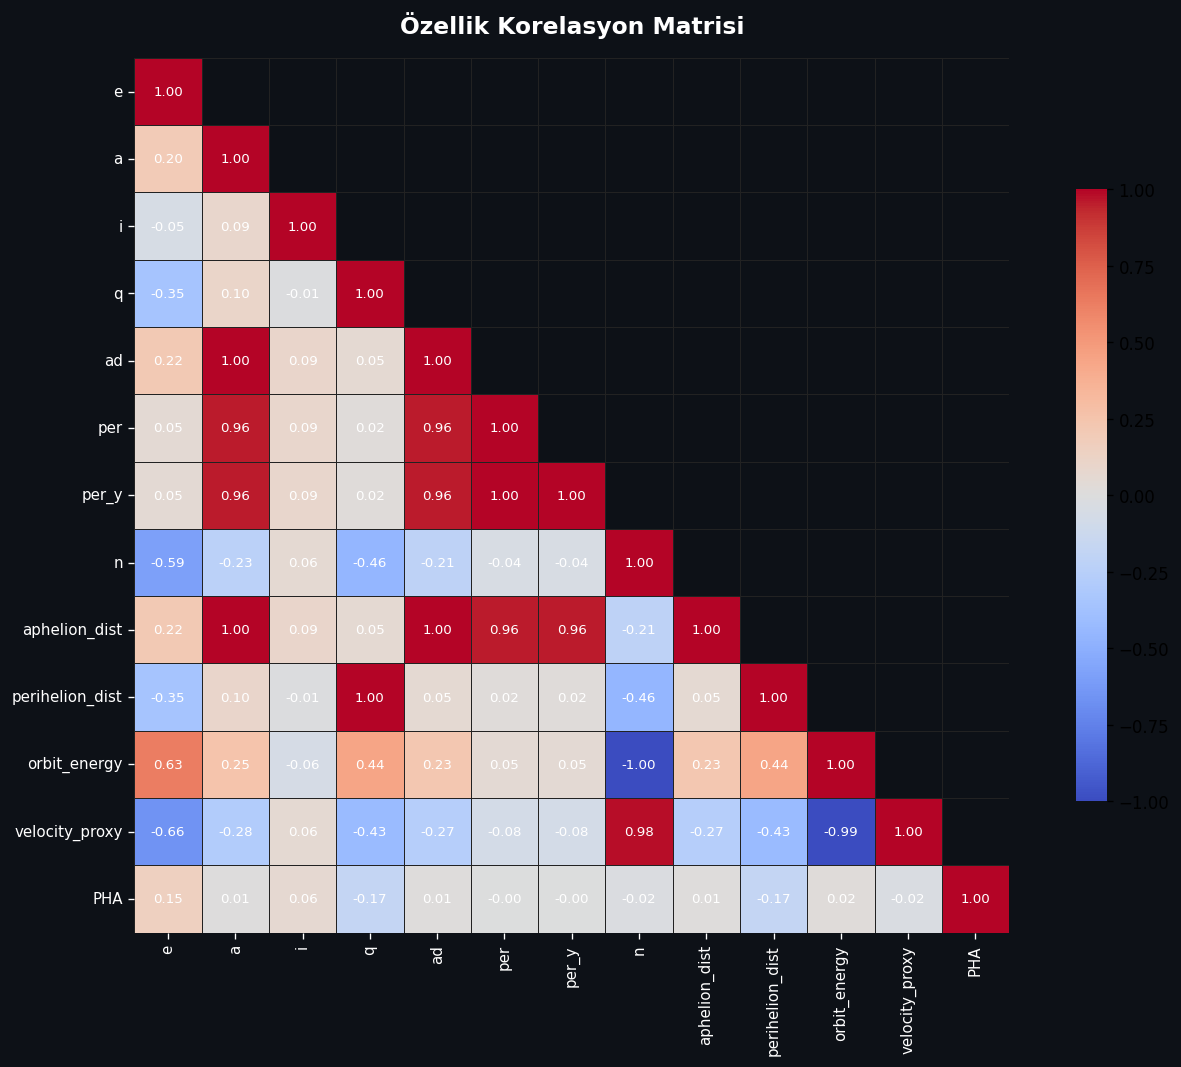

📊 Korelasyon matrisi kaydedildi: 04_correlation.png


In [12]:
# ============================================================
# 12. GÖRSELLEŞTİRME IV — Korelasyon Matrisi
# ============================================================

fig, ax = plt.subplots(figsize=(12, 9))
fig.patch.set_facecolor(SPACE_BG)
ax.set_facecolor(SPACE_BG)

corr_df = pd.DataFrame(X_train_raw_sc, columns=feature_names)
corr_df['PHA'] = y_train_raw.values
corr = corr_df.corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, ax=ax,
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'fontsize': 8, 'color': 'white'},
    linewidths=0.5, linecolor='#222222',
    square=True, cbar_kws={'shrink': 0.7}
)
ax.set_title('Özellik Korelasyon Matrisi',
             color='white', fontsize=14, fontweight='bold', pad=15)
ax.tick_params(colors='white', labelsize=9)

plt.tight_layout()
plt.savefig('04_correlation.png', dpi=130, bbox_inches='tight', facecolor=SPACE_BG)
plt.show()
print('📊 Korelasyon matrisi kaydedildi: 04_correlation.png')

In [13]:
# ============================================================
# 13. ÖZET RAPOR
# ============================================================

print('=' * 60)
print('   🌍 NASA ASTEROID PHA TESPİTİ — SONUÇ RAPORU')
print('=' * 60)
print()

def star(val, threshold=0.95):
    return '✅' if val >= threshold else '⚠️ '

print('📌 RANDOM FOREST:')
print(f'   {star(rf_acc)}  Accuracy  : %{rf_acc*100:.2f}')
print(f'   {star(rf_f1)}  F1 Score  : %{rf_f1*100:.2f}')
print(f'   {star(rf_auc)} ROC-AUC   : {rf_auc:.4f}')
print(f'   📊  CV Ort.   : %{rf_cv.mean()*100:.2f} (±{rf_cv.std()*100:.2f})')
print()
print('📌 XGBOOST:')
print(f'   {star(xgb_acc)}  Accuracy  : %{xgb_acc*100:.2f}')
print(f'   {star(xgb_f1)}  F1 Score  : %{xgb_f1*100:.2f}')
print(f'   {star(xgb_auc)} ROC-AUC   : {xgb_auc:.4f}')
print(f'   📊  CV Ort.   : %{xgb_cv.mean()*100:.2f} (±{xgb_cv.std()*100:.2f})')
print()
print('🏆 KAZANAN MODEL: ', end='')
if xgb_auc > rf_auc:
    print(f'XGBoost (ROC-AUC: {xgb_auc:.4f})')
else:
    print(f'Random Forest (ROC-AUC: {rf_auc:.4f})')
print()
print('🔐 OVERFİTTİNG KONTROLÜ:')
print(f'   RF  fark: {abs(rf_train_f1-rf_f1)*100:.1f} puan  → ', end='')
print('SORUN YOK ✅' if abs(rf_train_f1-rf_f1)*100 < 10 else 'KONTROL ET ⚠️')
print(f'   XGB fark: {abs(xgb_train_f1-xgb_f1)*100:.1f} puan → ', end='')
print('SORUN YOK ✅' if abs(xgb_train_f1-xgb_f1)*100 < 10 else 'KONTROL ET ⚠️')
print()
print('📁 Kaydedilen görseller:')
for fname in ['01_eda.png', '02_model_performance.png',
               '03_feature_importance.png', '04_correlation.png']:
    print(f'   • {fname}')
print()
print('=' * 60)

   🌍 NASA ASTEROID PHA TESPİTİ — SONUÇ RAPORU

📌 RANDOM FOREST:
   ⚠️   Accuracy  : %78.16
   ⚠️   F1 Score  : %20.75
   ⚠️  ROC-AUC   : 0.7484
   📊  CV Ort.   : %1.88 (±0.66)

📌 XGBOOST:
   ⚠️   Accuracy  : %69.26
   ⚠️   F1 Score  : %21.33
   ⚠️  ROC-AUC   : 0.7649
   📊  CV Ort.   : %2.27 (±0.53)

🏆 KAZANAN MODEL: XGBoost (ROC-AUC: 0.7649)

🔐 OVERFİTTİNG KONTROLÜ:
   RF  fark: 75.5 puan  → KONTROL ET ⚠️
   XGB fark: 62.2 puan → KONTROL ET ⚠️

📁 Kaydedilen görseller:
   • 01_eda.png
   • 02_model_performance.png
   • 03_feature_importance.png
   • 04_correlation.png

